# RQ08 — deployment rework rate (Issue #69)

A *rework rate* de cada repositório é a proporção de releases publicadas que a heurística final da RQ03(b) classifica como corretivas. A comparação usa o CFR (b), que atribui a falha à release anterior quando uma corretiva aparece nos sete dias seguintes.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import spearmanr, wilcoxon

ANALISE = Path.cwd()
CODE = ANALISE.parent / 'code'
FIGURAS = ANALISE / 'figuras'
TABELAS = ANALISE / 'tabelas'
FIGURAS.mkdir(exist_ok=True)
TABELAS.mkdir(exist_ok=True)

df = pd.read_csv(CODE / 'data' / 'dataset_dora.csv')
assert np.allclose(
    df['rework_rate'], df['releases_corretivas'] / df['n_releases'],
    equal_nan=True,
)
print(f'{len(df)} repositórios; fórmula de rework rate conferida')

Could not save font_manager cache [Errno 13] Permission denied: 'C:\\Users\\MatheusGastonVianaSi\\AppData\\Local\\matplotlib\\fontlist-v3.11.0.json.matplotlib-lock'


300 repositórios; fórmula de rework rate conferida


## Mediana e IQR

In [2]:
ROTULOS = {'rework_rate': 'Rework rate', 'cfr_b': 'CFR (b)'}
linhas = []
for coluna, rotulo in ROTULOS.items():
    valores = df[coluna].dropna() * 100
    q1, mediana, q3 = valores.quantile([0.25, 0.50, 0.75])
    linhas.append({
        'metrica': rotulo, 'n': len(valores), 'mediana_pct': mediana,
        'q1_pct': q1, 'q3_pct': q3, 'iqr_pontos_percentuais': q3 - q1,
    })
resumo = pd.DataFrame(linhas)
resumo.to_csv(TABELAS / 'rq08_resumo.csv', index=False)
resumo

,metrica,n,mediana_pct,q1_pct,q3_pct,iqr_pontos_percentuais
0,Rework rate,300,14.285714,2.653061,28.958333,26.305272
1,CFR (b),300,12.500000,0.000000,30.194805,30.194805


## Comparação pareada com o CFR (b)

In [3]:
pareados = df[['full_name', 'rework_rate', 'cfr_b']].dropna().copy()
diferenca = pareados['rework_rate'] - pareados['cfr_b']
rho, p_spearman = spearmanr(pareados['rework_rate'], pareados['cfr_b'])
estatistica_w, p_wilcoxon = wilcoxon(pareados['rework_rate'], pareados['cfr_b'])

comparacao = pd.DataFrame([{
    'n_pares': len(pareados),
    'rework_maior': int((diferenca > 0).sum()),
    'iguais': int((diferenca == 0).sum()),
    'rework_menor': int((diferenca < 0).sum()),
    'mediana_diferenca_pontos_percentuais': 100 * diferenca.median(),
    'spearman_rho': rho,
    'spearman_p': p_spearman,
    'wilcoxon_estatistica': estatistica_w,
    'wilcoxon_p': p_wilcoxon,
    'rework_agregada_pct': 100 * df['releases_corretivas'].sum() / df['n_releases'].sum(),
}])
comparacao.to_csv(TABELAS / 'rq08_comparacao_cfr_b.csv', index=False)
comparacao.T

,0
n_pares,3.000000e+02
rework_maior,9.800000e+01
iguais,9.800000e+01
rework_menor,1.040000e+02
mediana_diferenca_pontos_percentuais,0.000000e+00
spearman_rho,6.971957e-01
spearman_p,5.530972e-45
wilcoxon_estatistica,9.830500e+03
wilcoxon_p,6.127825e-01
rework_agregada_pct,2.524777e+01


## Distribuições e relação pareada

O violino mostra a densidade completa e recebe os quartis, a mediana e os pontos individuais. O segundo painel preserva a natureza pareada da comparação: pontos acima da diagonal têm *rework rate* maior que o CFR (b).

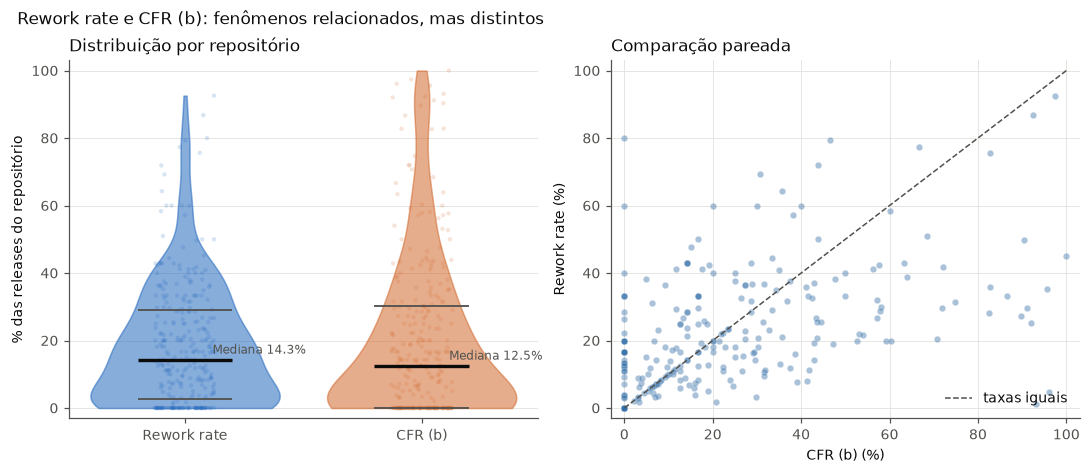

In [4]:
TEXTO, TEXTO_2, GRADE = '#0b0b0b', '#52514e', '#e4e3df'
CORES = ['#256abf', '#d26a2e']
plt.rcParams.update({
    'figure.dpi': 110, 'savefig.dpi': 200, 'savefig.bbox': 'tight', 'font.size': 9,
    'axes.edgecolor': TEXTO_2, 'axes.labelcolor': TEXTO, 'text.color': TEXTO,
    'xtick.color': TEXTO_2, 'ytick.color': TEXTO_2,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.color': GRADE, 'grid.linewidth': 0.6, 'axes.axisbelow': True,
})

valores = [pareados['rework_rate'].to_numpy() * 100, pareados['cfr_b'].to_numpy() * 100]
fig, (ax_v, ax_p) = plt.subplots(1, 2, figsize=(9.8, 4.2), layout='constrained')

partes = ax_v.violinplot(
    valores, positions=[1, 2], widths=0.8, showmeans=False, showmedians=True,
    showextrema=False, quantiles=[[0.25, 0.75], [0.25, 0.75]],
)
for corpo, cor in zip(partes['bodies'], CORES):
    corpo.set_facecolor(cor)
    corpo.set_edgecolor(cor)
    corpo.set_alpha(0.55)
partes['cmedians'].set_color(TEXTO)
partes['cmedians'].set_linewidth(2.2)
partes['cquantiles'].set_color(TEXTO_2)
partes['cquantiles'].set_linewidth(1.2)
rng = np.random.default_rng(42)
for posicao, serie, cor in zip([1, 2], valores, CORES):
    ax_v.scatter(
        posicao + rng.uniform(-0.13, 0.13, len(serie)), serie,
        s=8, alpha=0.18, color=cor, edgecolors='none', rasterized=True,
    )
    ax_v.annotate(
        f'Mediana {np.median(serie):.1f}%', (posicao, np.median(serie)),
        xytext=(18, 4), textcoords='offset points', fontsize=8, color=TEXTO_2,
    )
ax_v.set_xticks([1, 2], ['Rework rate', 'CFR (b)'])
ax_v.set_ylabel('% das releases do repositório')
ax_v.set_ylim(-3, 103)
ax_v.set_title('Distribuição por repositório', loc='left')
ax_v.grid(axis='x', visible=False)

ax_p.scatter(
    pareados['cfr_b'] * 100, pareados['rework_rate'] * 100,
    s=18, alpha=0.42, color='#326fa8', edgecolors='white', linewidths=0.25,
)
ax_p.plot([0, 100], [0, 100], '--', color=TEXTO_2, linewidth=1, label='taxas iguais')
ax_p.set_xlim(-3, 103)
ax_p.set_ylim(-3, 103)
ax_p.set_xlabel('CFR (b) (%)')
ax_p.set_ylabel('Rework rate (%)')
ax_p.set_title('Comparação pareada', loc='left')
ax_p.legend(frameon=False, loc='lower right')

fig.suptitle('Rework rate e CFR (b): fenômenos relacionados, mas distintos', x=0.01, ha='left')
fig.savefig(FIGURAS / 'rq08_rework_vs_cfr.png')

## Síntese

A *rework rate* mediana é 14,3% (Q1 = 2,7%; Q3 = 29,0%; IQR = 26,3 pontos percentuais), contra CFR (b) mediano de 12,5% (Q1 = 0%; Q3 = 30,2%). As métricas têm associação positiva (Spearman ρ = 0,697), mas não há deslocamento pareado sistemático (Wilcoxon p = 0,613; diferença mediana = 0 p.p.): a *rework rate* é maior em 98 repositórios, igual em 98 e menor em 104. A taxa agregada de 25,2% não deve ser confundida com a mediana por repositório, porque dá mais peso aos projetos que publicam muitas releases.